# Ejercicios de Seaborn

# 1. Importa pandas, pyplot y seaborn

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Lee 'Pokemon.csv', lee la primera columna del csv como índice del DataFrame

In [2]:
pokemon = pd.read_csv('data/Pokemon.csv', index_col=0)

# 4. Mira las primeras filas del dataset para hacerte una idea de los datos cargados

In [3]:
pokemon.head()

,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Stage,Legendary
#,,,,,,,,,,,,
1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,2,False
3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,3,False
4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False
5,Charmeleon,Fire,NaN,405,58,64,58,80,65,80,2,False


# 5. Haz un scatter plot con lmplot(), que es el método que pinta una regresión lineal
### Pasa el DataFrame como argumento del método en el parámetro llamado data

c:\Users\julio\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


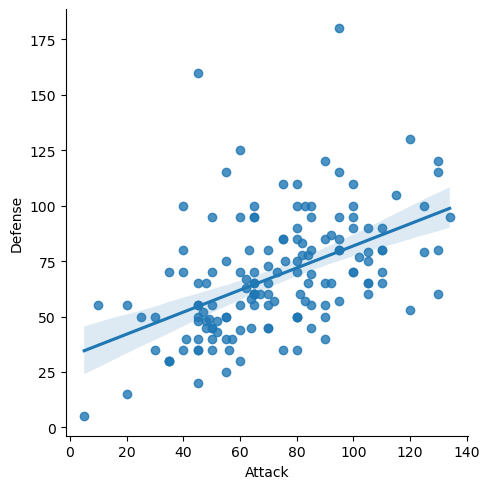

In [4]:
sns.lmplot(data=pokemon, x='Attack', y='Defense');

# 6. No queremos ver la línea recta de la regresión lineal.
### prueba a añadir fit_reg a falso

c:\Users\julio\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


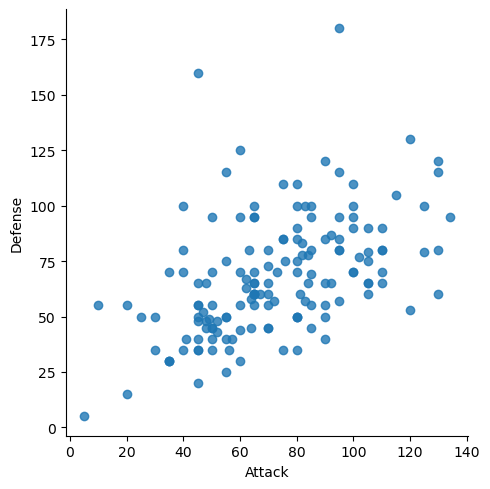

In [5]:
sns.lmplot(data=pokemon, x='Attack', y='Defense', fit_reg=False);

# 7. Vamos a decir qué variable (columna del DataFrame) codifica los colores (hue)
### Que el hue sea el Stage

c:\Users\julio\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


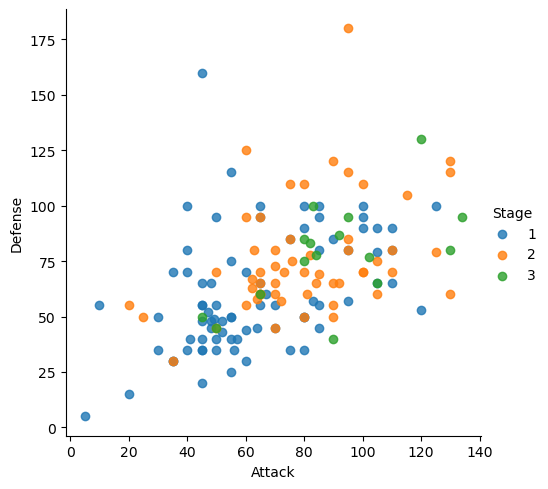

In [6]:
sns.lmplot(data=pokemon, x='Attack', y='Defense', fit_reg=False, hue='Stage');

# 8. Limita el eje x entre 20 y 100

c:\Users\julio\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


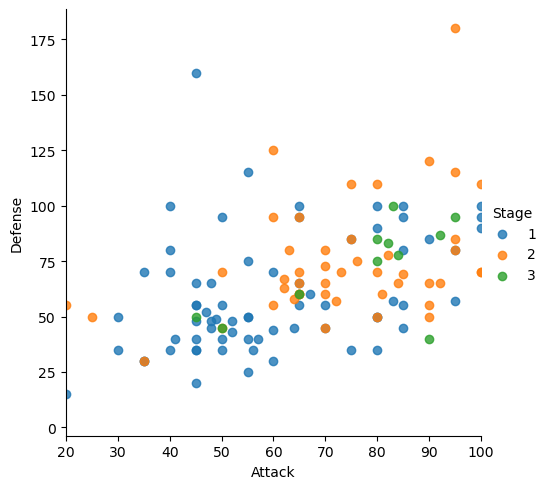

In [7]:
sns.lmplot(data=pokemon, x='Attack', y='Defense', fit_reg=False, hue='Stage');
plt.xlim(20,100);

# 9. Dibuja un diagrama de cajas con el dataframe

<Axes: >

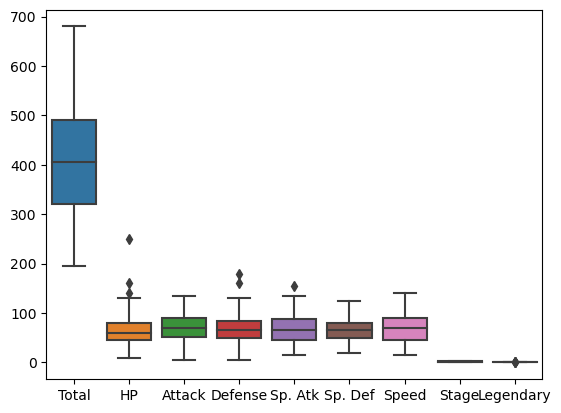

In [8]:
sns.boxplot(data=pokemon)

# 10. No nos interesan las columnas Total, Stage ni Legendary
### Bórralos del DataFrame y vuelve a dibujar el diagrama de cajas

<Axes: >

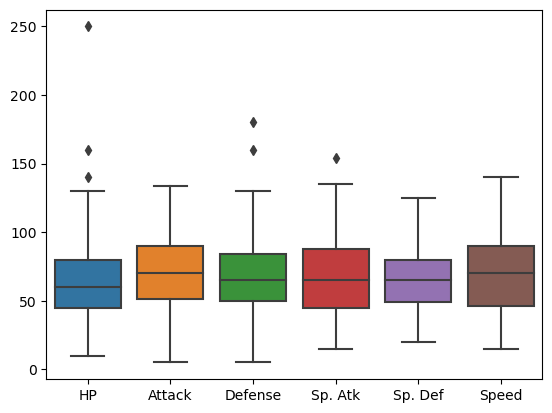

In [9]:
pokemon10 = pokemon.drop(columns=['Total', 'Stage', 'Legendary'])
sns.boxplot(data=pokemon10)

# 11. Mira cuántos 'Type 1' diferentes hay en el DataFrame

In [10]:
pokemon['Type 1'].unique()
pokemon['Type 1'].nunique()

15

# 12. Quédate del Dataframe solo con los 'Type 1' iguales a 'Grass', 'Fire' o 'Water'

In [14]:
pokemon12 = pokemon10[pokemon10['Type 1'].isin(['Grass', 'Fire', 'Water'])]
pokemon12.shape

(52, 9)

# 13. Usa un estilo 'whitegrid'

In [15]:
sns.set_style('whitegrid')

# 14. Pinta diagramas de violín con el DataFrame filtrado por los 3 tipos

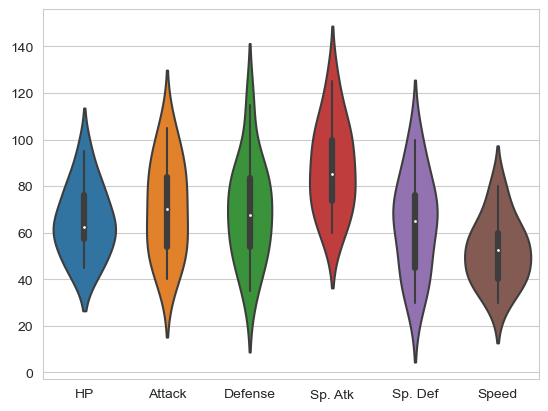

In [16]:
sns.violinplot(data=pokemon12[pokemon12['Type 1']=='Grass']);

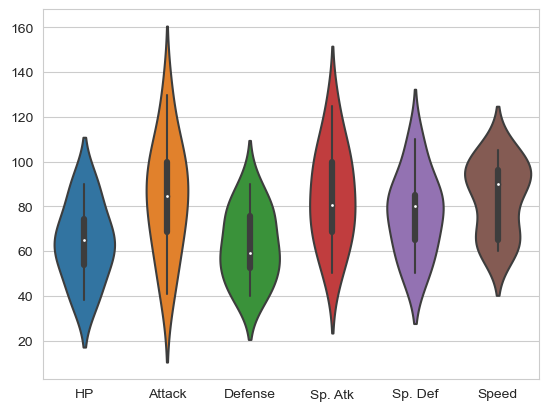

In [17]:
sns.violinplot(data=pokemon12[pokemon12['Type 1']=='Fire']);

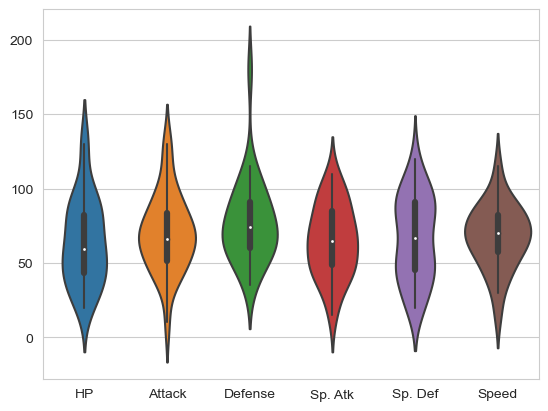

In [18]:
sns.violinplot(data=pokemon12[pokemon12['Type 1']=='Water']);

# 15. Escribe una lista de colores con valores '#78C850', '#F08030',  '#6890F0'

In [19]:
colores = ['#78C850', '#F08030', '#6890F0']

# 16. Pinta de nuevo los diagramas de violín añadiendo esos colores en la paleta (palette)

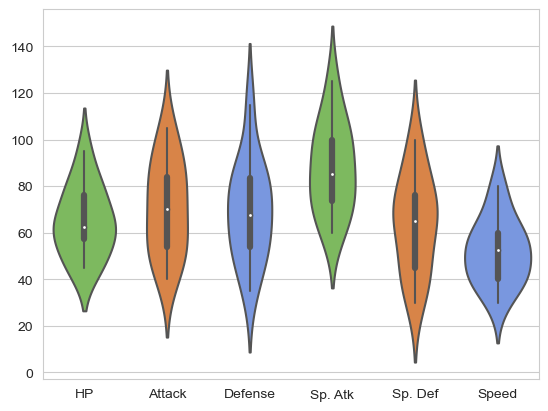

In [20]:
sns.violinplot(data=pokemon12[pokemon12['Type 1']=='Grass'], palette=colores);

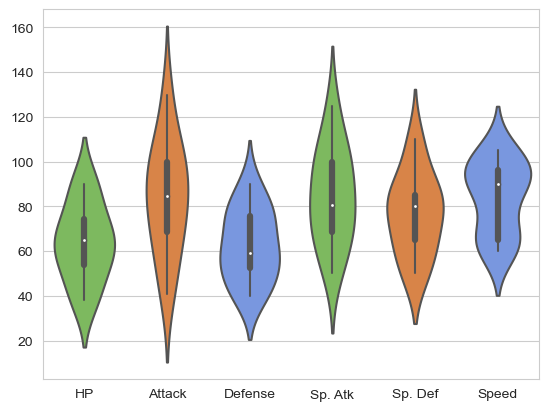

In [21]:
sns.violinplot(data=pokemon12[pokemon12['Type 1']=='Fire'], palette=colores);

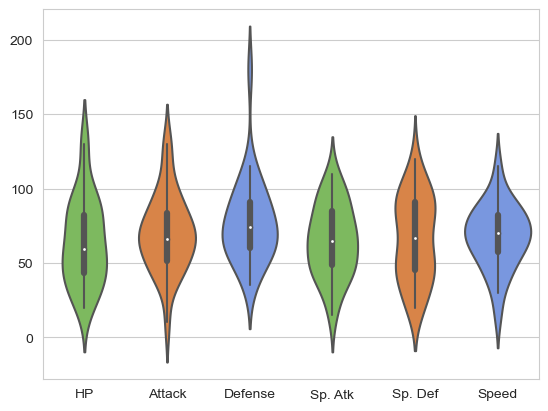

In [22]:
sns.violinplot(data=pokemon12[pokemon12['Type 1']=='Water'], palette=colores);

# 17. Con el diagrama de violín vemos la forma de la distribución, pero no sabemos si Grass tiene muchos puntos y Fire tiene muy pocos.
### Para ver esto, usamos el swarmplot.
### Pinta el último diagrama de violines pero con un swarmplot en lugar de un violin

<Axes: >

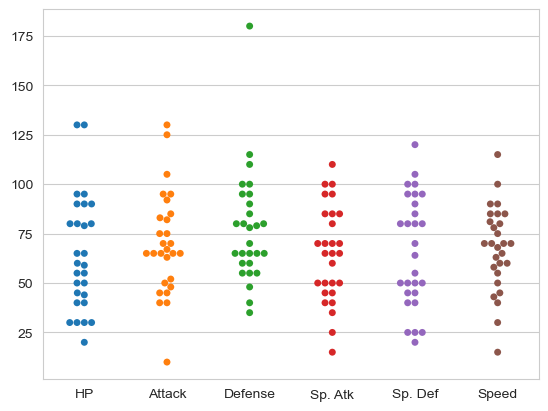

In [23]:
sns.swarmplot(data=pokemon12[pokemon12['Type 1']=='Water'])

# 18. Queremos ver los violines a la vez que los swarm, los podemos pintar juntos. 
### Elimina los diagramas de caja dentro de los violines con el parámetro inner = None y pon una transparencia de 0.9 en el swarmplot
### Pon un título con pyplot (como siempre)

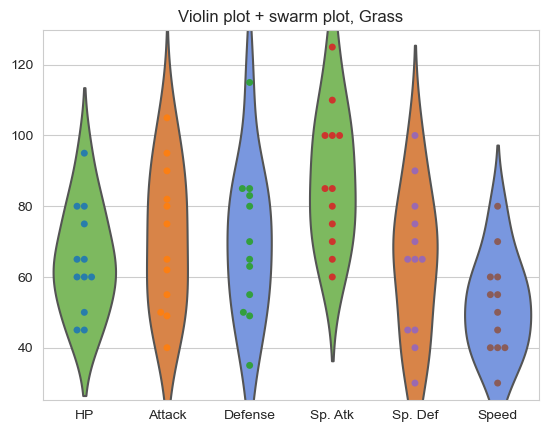

In [24]:
plt.figure
sns.violinplot(data=pokemon12[pokemon12['Type 1']=='Grass'], palette=colores, inner=None);
sns.swarmplot(data=pokemon12[pokemon12['Type 1']=='Grass'], alpha=0.9)
plt.title('Violin plot + swarm plot, Grass');

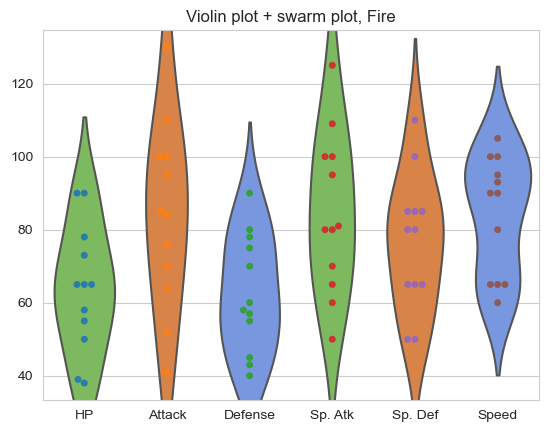

In [25]:
plt.figure
sns.violinplot(data=pokemon12[pokemon12['Type 1']=='Fire'], palette=colores, inner=None);
sns.swarmplot(data=pokemon12[pokemon12['Type 1']=='Fire'], alpha=0.9)
plt.title('Violin plot + swarm plot, Fire');

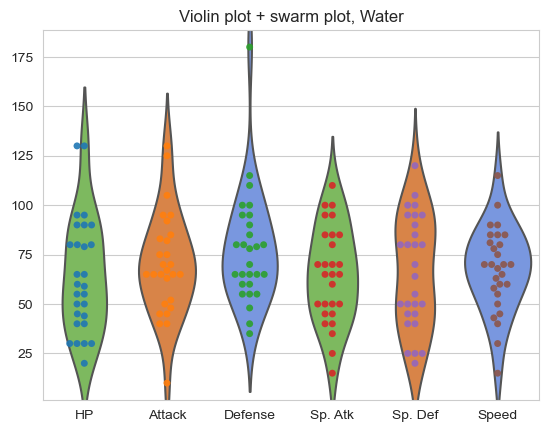

In [26]:
plt.figure
sns.violinplot(data=pokemon12[pokemon12['Type 1']=='Water'], palette=colores, inner=None);
sns.swarmplot(data=pokemon12[pokemon12['Type 1']=='Water'], alpha=0.9)
plt.title('Violin plot + swarm plot, Water');

# 19. Veamos la función melt() de pandas. Melt toma los valores de varias columnas y los junta todos en una misma columna nueva.
### Dado un DataFrame, melt recibe varios parámetros:
### * qué columnas del DataFrame se quedan igual
### * qué nombres de columnas del dataframe pasan a ser una columna nueva
### * cómo queremos llamar esas nuevas columnas

### Primero recuerda el Dataframe df_grass_fire_water con las primeras 5 filas

In [27]:
pokemon12.head()

,Name,Type 1,Type 2,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed
#,,,,,,,,,
1,Bulbasaur,Grass,Poison,45,49,49,65,65,45
2,Ivysaur,Grass,Poison,60,62,63,80,80,60
3,Venusaur,Grass,Poison,80,82,83,100,100,80
4,Charmander,Fire,NaN,39,52,43,60,50,65
5,Charmeleon,Fire,NaN,58,64,58,80,65,80


# 20. Queremos dejar igual las variables 'Name' y 'Type 1'
### Queremos añadir una columa nueva cuyos valores sean las columnas que queremos apilar y que se llame 'New Column'
### Escribimos df_gfw.melt(id_vars=['Name', 'Type 1'], value_vars=[...], var_name='New Column')

In [28]:
pokemon20 = pokemon12.melt(id_vars=['Name', 'Type 1'], value_vars=['HP', 'Attack', 'Defense'], var_name='New Column')

# 21. Pintamos el swarmplot con el melted y entendemos la información

<Axes: >

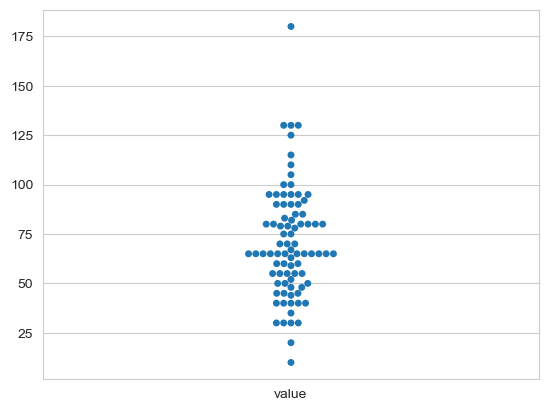

In [29]:
sns.swarmplot(data=pokemon20[pokemon20['Type 1']=='Water'])

# 22. Basándote en el gráfico anterior, define el tamaño de la figura en (10,6) (usa plt)
### En el swarmplot añade el argumento dodge a True y usa la anterior paleta de colores Pokemon

### Dodge en inglés es "esquivar", ¿qué diferencia ves?

## Usando plt 
### fija el límite del eje Y entre 0 y 200
### fija la leyenda con bbox_to_anchor en upper left. Pista: upper left es el código 2 y se usa el parámetro loc.

### Observa que incluso usando Seaborn, usamos Pyplot para trabajar con los ejes, la leyenda y el tamaño
### Lo importante es que Seaborn y Pyplot conviven bien juntos

C:\Users\julio\AppData\Local\Temp\ipykernel_19484\3829744773.py:2: UserWarning: The palette list has more values (3) than needed (1), which may not be intended.
  sns.swarmplot(data=pokemon20[pokemon20['Type 1']=='Water'], dodge=True, palette=colores);
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


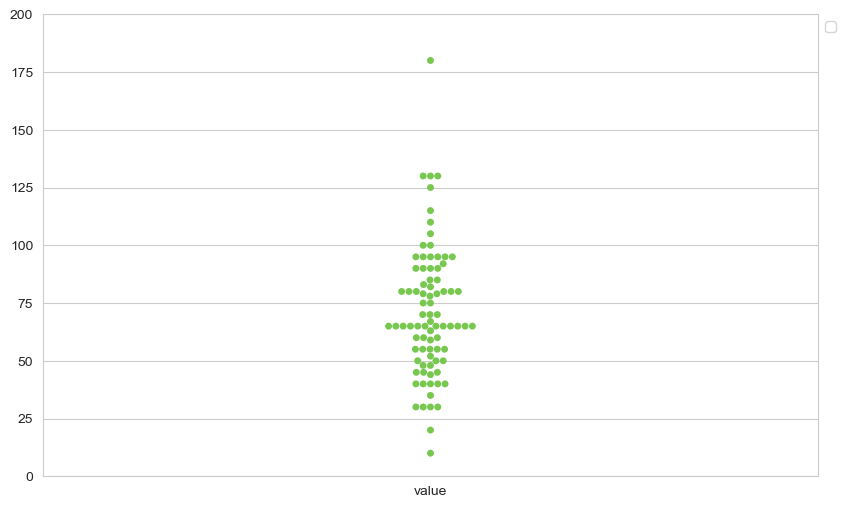

In [30]:
plt.figure(figsize=(10,6))
sns.swarmplot(data=pokemon20[pokemon20['Type 1']=='Water'], dodge=True, palette=colores);
plt.ylim(0, 200)
plt.legend(bbox_to_anchor=(1,1), loc=2);

# 23. Mapas de calor
### Calcula las correlaciones del primer DataFrame original df
### Pista: las correlaciones se calculan con el método corr()
### Recuerda: las correlaciones miden entre dos variables, si varío una, cuánto me varía la otra (cómo están de relacionadas)

In [31]:
pokemon.corr(numeric_only=True)

,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Stage,Legendary
Total,1.000000,0.576591,0.670939,0.508694,0.680745,0.774383,0.506950,0.504224,0.328412
HP,0.576591,1.000000,0.306768,0.119782,0.236649,0.490978,-0.040939,0.249207,0.172441
Attack,0.670939,0.306768,1.000000,0.491965,0.146312,0.369069,0.194701,0.361321,0.147486
Defense,0.508694,0.119782,0.491965,1.000000,0.187569,0.139912,-0.053252,0.270861,0.141576
Sp. Atk,0.680745,0.236649,0.146312,0.187569,1.000000,0.522907,0.411516,0.391712,0.334159
Sp. Def,0.774383,0.490978,0.369069,0.139912,0.522907,1.000000,0.392656,0.358308,0.215314
Speed,0.506950,-0.040939,0.194701,-0.053252,0.411516,0.392656,1.000000,0.240042,0.199969
Stage,0.504224,0.249207,0.361321,0.270861,0.391712,0.358308,0.240042,1.000000,-0.142508
Legendary,0.328412,0.172441,0.147486,0.141576,0.334159,0.215314,0.199969,-0.142508,1.000000


### ¿la correlación entre qué valores se encuentra?
### la autocorrelación es la correlación de una variable consigo misma, ¿qué aprecias?
### Encuentra dos variables que veas que están fuertemente relacionadas según la correlación

La correlación se encuentra entre -1 y 1. 

Las autocorrelaciones valen 1. 

Las variables más fuertemente relacionadas (según correlación de Pearson) son Total y Sp. Def. 

# 24. Pinta el histograma y la densidad de probabilidad del nivel de defensa usando el DataFrame original

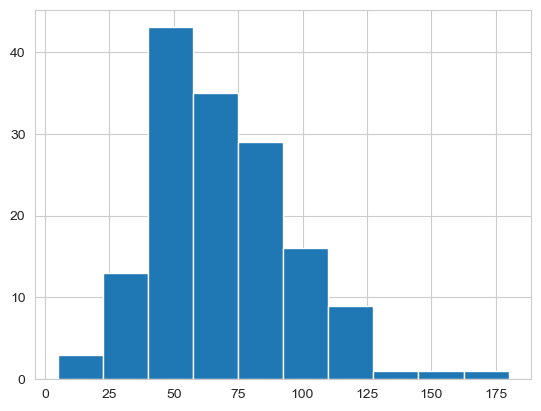

In [32]:
pokemon['Defense'].hist();

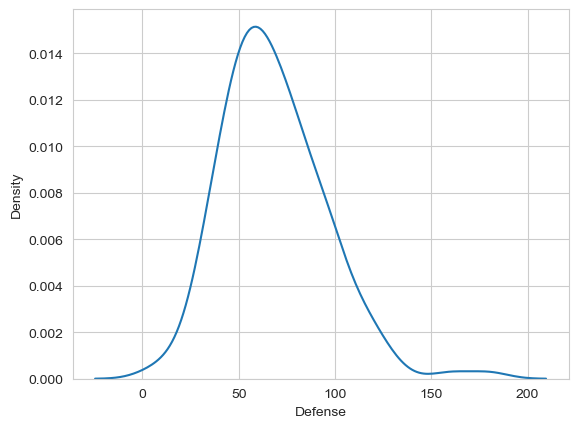

In [33]:
sns.kdeplot(pokemon['Defense']);

# 25. Pinta un diagrama de barras de la columna 'Type 1' usando el DataFrame original
### Usa un sns.countplot
### Usa plt.xticks y gira las etiquetas

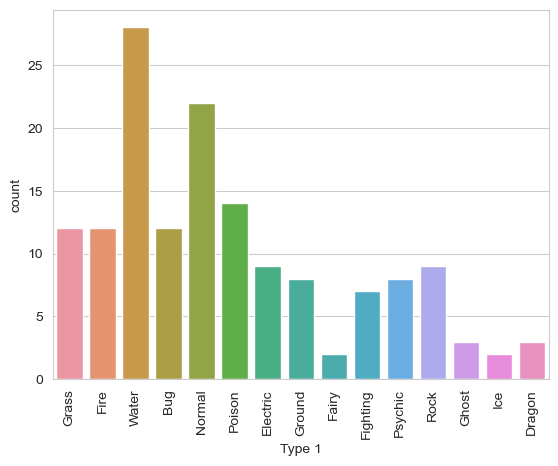

In [34]:
sns.countplot(data=pokemon, x='Type 1');
plt.xticks(rotation=90);

# 26. Usa catplot con el DataFrame original.
### Muestra el valor de Defense según el 'Type 1', muestra un subplot para legendarios y otro para no legendarios y divide los colores según el Type 2

c:\Users\julio\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


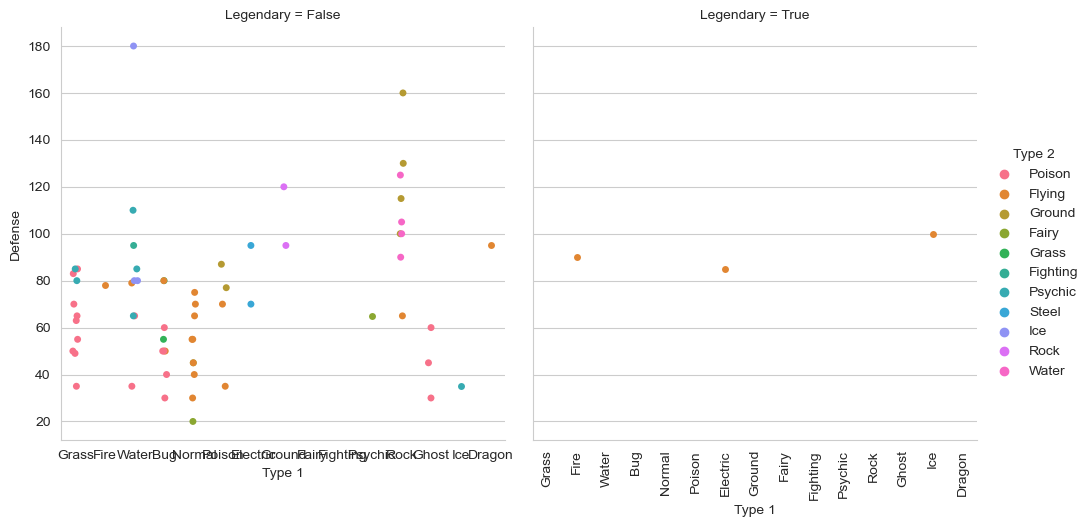

In [35]:
sns.catplot(data=pokemon, x='Type 1', col='Legendary', col_wrap=2, y='Defense', hue='Type 2', sharex=True);
plt.xticks(rotation=90);

# 27. Muestra una función distribución de probabilidad con kdeplot (curvas de nivel) de la defensa respecto al ataque.
### Di un bin 2D donde caigan muchos puntos (ataque, defensa).

Bin 2D donde caen muchos puntos (ataque, defensa): (60, 55)


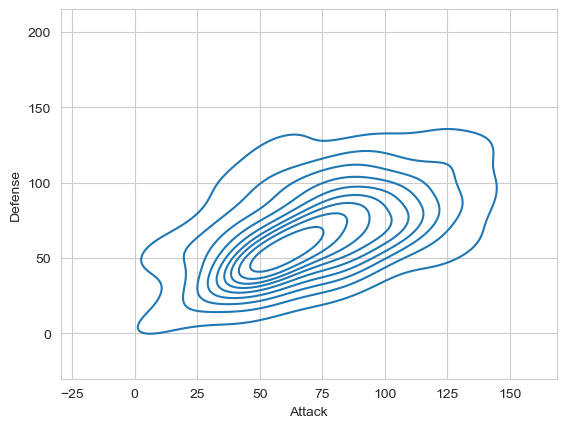

In [37]:
sns.kdeplot(data=pokemon, x='Attack', y='Defense',);
print('Bin 2D donde caen muchos puntos (ataque, defensa): (60, 55)')

# 28. Pinta una distribución de probabilidad conjunta con jointplot, pintando la defensa respecto al ataque del DataFrame original

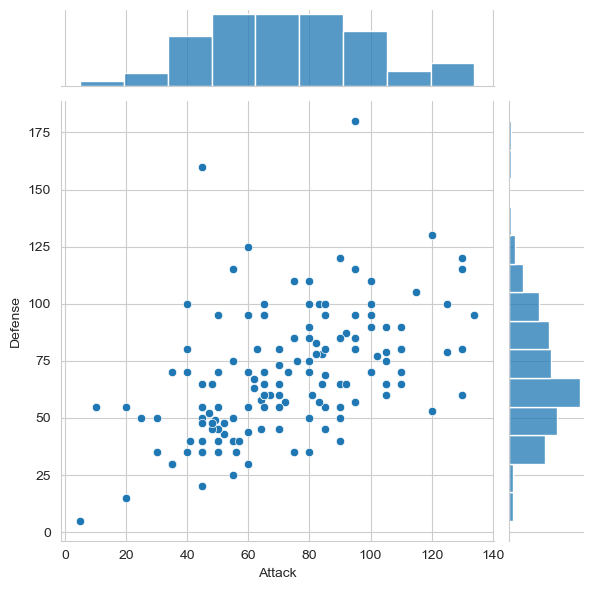

In [38]:
sns.jointplot(data=pokemon, x='Attack', y='Defense');